# AlertaSP — Previsão de registros de alagamento em São Paulo

**Global Solution FIAP 2026.2 · CitizenTech · Inteligência Artificial & Machine Learning**

**Pergunta de ML:** com os dados meteorológicos observados até o fim de hoje, é possível estimar se haverá
pelo menos um registro de alagamento ou inundação no município de São Paulo **amanhã**?

- **Tipo de problema:** classificação binária (`alvo_registro_amanha`: 1 = há registro no dia seguinte).
- **Dados reais e públicos:**
  - INMET — estações automáticas A701 (Mirante) e A771 (Interlagos): chuva, temperatura e umidade. <https://portal.inmet.gov.br/dadoshistoricos>
  - GeoSampa / Defesa Civil — registros de alagamentos e inundações. <https://metadados.geosampa.prefeitura.sp.gov.br/geonetwork/srv/api/records/432c06b1-03a1-4b1f-9210-423e1b58e869>
- **Preparação:** feita pelos scripts `ml/scripts/01` a `07` (download, limpeza, conversão UTC → horário de SP,
  agregação diária, cruzamento por data e criação das 12 features). Detalhes em `ml/dados/README.md`.
- **Divisão temporal (sem embaralhar):**

| Conjunto | Período | Uso |
|---|---|---|
| Treino | 2022–2024 | Ajuste do modelo e validação cruzada |
| Teste | 2025 | Avaliação final, fora da busca de hiperparâmetros |
| Provisório | 2026 | Não usado (cobertura da fonte ainda não confirmada) |

## 1. Carregamento dos dados preparados

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline

# Encontrar a pasta ML
candidatos = [
    Path.cwd(),
    Path.cwd() / "ML",
    Path.cwd().parent,
]

BASE = next(
    (
        pasta for pasta in candidatos
        if (pasta / "dados/modelagem/treino_2022_2024.csv").exists()
    ),
    None,
)

if BASE is None:
    raise FileNotFoundError("Pasta de dados do AlertaSP não encontrada.")

DADOS = BASE / "dados/modelagem"
RESULTADOS = BASE / "resultados"
RESULTADOS.mkdir(exist_ok=True)

ALVO = "alvo_registro_amanha"

treino = pd.read_csv(
    DADOS / "treino_2022_2024.csv",
    parse_dates=["data"],
).sort_values("data")

teste = pd.read_csv(
    DADOS / "teste_2025.csv",
    parse_dates=["data"],
).sort_values("data")

FEATURES = [
    coluna for coluna in treino.columns
    if coluna not in ("data", ALVO)
]

X_treino = treino[FEATURES]
y_treino = treino[ALVO].astype(int)

X_teste = teste[FEATURES]
y_teste = teste[ALVO].astype(int)

assert len(FEATURES) == 12
assert treino["data"].max() < teste["data"].min()

print("Treinamento:", len(treino))
print("Teste 2025:", len(teste))
print("Features:", len(FEATURES))

display(treino.head())

Treinamento: 1093
Teste 2025: 364
Features: 12


,data,chuva_mm_a701,temperatura_media_c_a701,umidade_media_pct_a701,chuva_acumulada_3d_a701,chuva_acumulada_7d_a701,chuva_mm_a771,temperatura_media_c_a771,umidade_media_pct_a771,chuva_acumulada_3d_a771,chuva_acumulada_7d_a771,dia_ano_seno,dia_ano_cosseno,alvo_registro_amanha
0,2022-01-01,3.6,21.083333,81.875000,NaN,NaN,0.6,21.450000,88.500000,NaN,NaN,0.017202,0.999852,1
1,2022-01-02,2.8,22.875000,76.583333,NaN,NaN,0.0,23.141667,82.666667,NaN,NaN,0.034398,0.999408,1
2,2022-01-03,19.8,22.537500,82.083333,26.2,NaN,1.0,22.970833,85.625000,1.6,NaN,0.051584,0.998669,1
3,2022-01-04,15.0,22.570833,81.875000,37.6,NaN,13.2,22.362500,93.333333,14.2,NaN,0.068755,0.997634,1
4,2022-01-05,4.8,22.904167,76.541667,39.6,NaN,12.0,23.233333,87.208333,26.2,NaN,0.085906,0.996303,1


## 2. Modelo e busca de hiperparâmetros

**Por que Random Forest:** a relação entre chuva acumulada, umidade, temperatura e época do ano não é linear;
o Random Forest captura essas interações sem exigir normalização, é robusto a ruído, permite controlar a
complexidade (`max_depth`, `min_samples_leaf`) e oferece leitura da importância das variáveis.

- 12 combinações de 3 hiperparâmetros: `n_estimators` (100, 200, 300) × `max_depth` (5, 10) × `min_samples_leaf` (2, 5).
- Validação cruzada **somente no treino**, com `TimeSeriesSplit` (4 divisões, `gap=1`) — cada dobra valida em um período posterior ao de treino.
- Métrica de seleção: **Average Precision**, adequada para classes desbalanceadas (~30% de dias positivos no treino).
- `SimpleImputer` dentro do `Pipeline`, para que a mediana seja calculada apenas com os dados de treino de cada dobra.

In [2]:
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    (
        "modelo",
        RandomForestClassifier(
            random_state=42,
            class_weight="balanced_subsample",
            n_jobs=1,
        ),
    ),
])

parametros = {
    "modelo__n_estimators": [100, 200, 300],
    "modelo__max_depth": [5, 10],
    "modelo__min_samples_leaf": [2, 5],
}

busca = GridSearchCV(
    estimator=pipeline,
    param_grid=parametros,
    scoring="average_precision",
    cv=TimeSeriesSplit(n_splits=4, gap=1),
    n_jobs=-1,
    return_train_score=True,
    refit=True,
)

busca.fit(X_treino, y_treino)

modelo = busca.best_estimator_

print("Melhores parâmetros:")
print(busca.best_params_)

print("\nAverage Precision média da validação cruzada:")
print(round(busca.best_score_, 4))

resultados_cv = pd.DataFrame(busca.cv_results_)

display(
    resultados_cv[
        [
            "params",
            "mean_train_score",
            "mean_test_score",
            "rank_test_score",
        ]
    ].sort_values("rank_test_score")
)

Melhores parâmetros:
{'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}

Average Precision média da validação cruzada:
0.6466


,params,mean_train_score,mean_test_score,rank_test_score
5,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.896499,0.646553,1
9,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.945852,0.645543,2
3,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.895010,0.645228,3
4,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.895729,0.643839,4
11,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.948324,0.643035,5
10,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.947928,0.643020,6
2,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.919974,0.640710,7
1,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.920315,0.638098,8
0,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.918024,0.637572,9
6,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.995168,0.621725,10


**Leitura da tabela:** as combinações com `max_depth=10` e `min_samples_leaf=2` chegam a Average Precision ≈ 0,99
no treino, mas ficam entre as piores na validação cruzada (≈ 0,62) — sinal claro de overfitting. As árvores mais
rasas e com folhas maiores (`max_depth=5`, `min_samples_leaf=5`) generalizam melhor e foram escolhidas.

## 3. Métricas em treino e teste (lado a lado)

In [3]:
def avaliar(nome, X, y):
    probabilidades = modelo.predict_proba(X)[:, 1]
    previsoes = (probabilidades >= 0.5).astype(int)

    return {
        "Conjunto": nome,
        "Accuracy": accuracy_score(y, previsoes),
        "Precision": precision_score(y, previsoes, zero_division=0),
        "Recall": recall_score(y, previsoes, zero_division=0),
        "F1": f1_score(y, previsoes, zero_division=0),
        "Average Precision": average_precision_score(y, probabilidades),
        "ROC-AUC": roc_auc_score(y, probabilidades),
    }


metricas = pd.DataFrame([
    avaliar("Treinamento", X_treino, y_treino),
    avaliar("Teste 2025", X_teste, y_teste),
])

display(metricas.round(4))

print("Referência AP 2025:", round(y_teste.mean(), 4))

metricas.to_csv(
    RESULTADOS / "10_metricas_notebook.csv",
    index=False,
)

,Conjunto,Accuracy,Precision,Recall,F1,Average Precision,ROC-AUC
0,Treinamento,0.8161,0.6427,0.8549,0.7338,0.8341,0.9132
1,Teste 2025,0.7527,0.4803,0.7176,0.5755,0.6237,0.8315


Referência AP 2025: 0.2335


**Overfitting:** a Average Precision cai de 0,83 no treino para 0,62 no teste de 2025. Há perda de generalização,
mas o modelo continua bem acima da referência sem discriminação (0,23 = proporção de dias positivos em 2025).

## 4. Matriz de confusão e curva Precision-Recall (teste 2025)

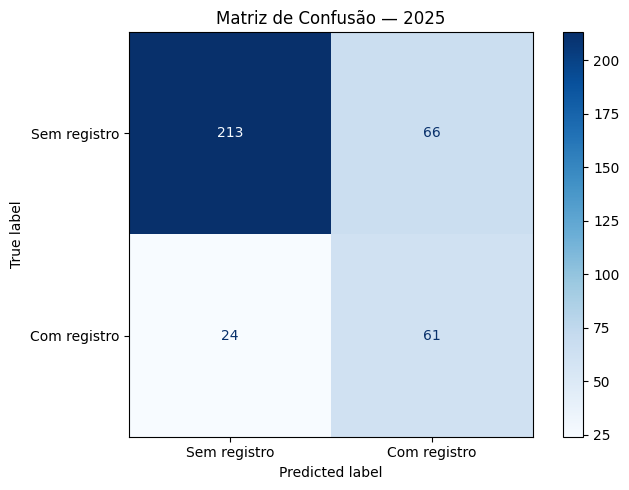

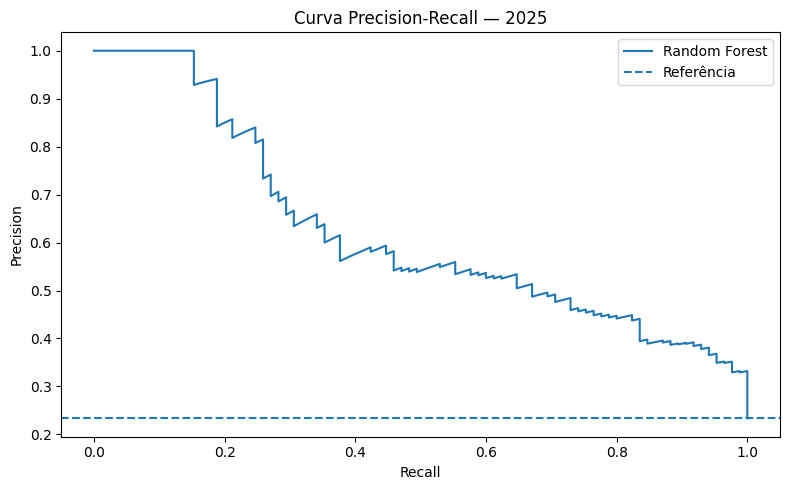

In [4]:
probabilidades = modelo.predict_proba(X_teste)[:, 1]
previsoes = (probabilidades >= 0.5).astype(int)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_teste,
    previsoes,
    labels=[0, 1],
    display_labels=["Sem registro", "Com registro"],
    cmap="Blues",
    ax=ax,
)

ax.set_title("Matriz de Confusão — 2025")
plt.tight_layout()
plt.show()


precision, recall, _ = precision_recall_curve(
    y_teste,
    probabilidades,
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(recall, precision, label="Random Forest")
ax.axhline(
    y_teste.mean(),
    linestyle="--",
    label="Referência",
)

ax.set_title("Curva Precision-Recall — 2025")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()

plt.tight_layout()
plt.show()

## 5. Importância das variáveis (permutação no teste 2025)

,feature,importancia_media,desvio_padrao
11,dia_ano_cosseno,0.092664,0.031576
6,temperatura_media_c_a771,0.049260,0.016314
10,dia_ano_seno,0.042907,0.013844
4,chuva_acumulada_7d_a701,0.032543,0.010215
1,temperatura_media_c_a701,0.024187,0.014876
3,chuva_acumulada_3d_a701,0.018463,0.009391
0,chuva_mm_a701,0.014358,0.005876
2,umidade_media_pct_a701,0.006731,0.004907
8,chuva_acumulada_3d_a771,0.004069,0.005453
5,chuva_mm_a771,0.003616,0.003826


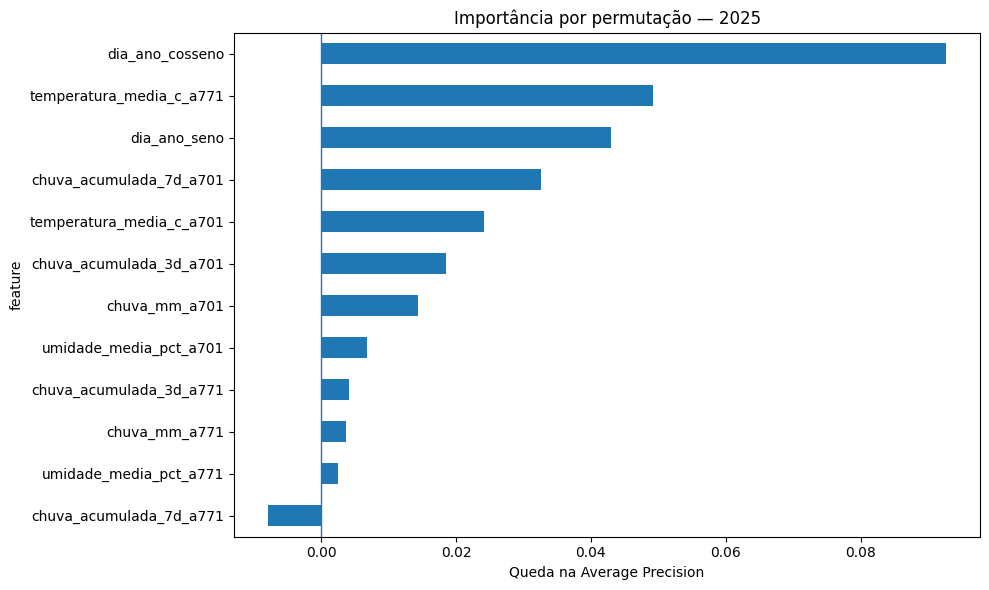

In [5]:
importancia = permutation_importance(
    modelo,
    X_teste,
    y_teste,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

tabela_importancia = pd.DataFrame({
    "feature": FEATURES,
    "importancia_media": importancia.importances_mean,
    "desvio_padrao": importancia.importances_std,
}).sort_values("importancia_media", ascending=False)

display(tabela_importancia)

fig, ax = plt.subplots(figsize=(10, 6))

tabela_importancia.sort_values(
    "importancia_media"
).plot.barh(
    x="feature",
    y="importancia_media",
    legend=False,
    ax=ax,
)

ax.axvline(0, linewidth=1)
ax.set_title("Importância por permutação — 2025")
ax.set_xlabel("Queda na Average Precision")

plt.tight_layout()
plt.show()

## 6. Conclusão — o que isso significa para o cidadão

- Em 2025, o modelo sinalizou corretamente **61 dos 85 dias** que tiveram registro de alagamento (recall ≈ 72%).
- Em compensação, cerca de metade dos alertas foram falsos positivos (precision ≈ 48%).
- Para quem se desloca pela cidade, isso significa um **aviso de “amanhã há risco elevado”** que acerta a maioria
  dos dias críticos, ao custo de alguns alarmes desnecessários — um custo aceitável para planejar trajeto, horário
  ou evitar áreas baixas.
- Época do ano, temperatura e chuva acumulada foram as variáveis mais relevantes.
- O modelo é diário e municipal (não por rua) e **não substitui** os alertas da Defesa Civil e do CGE.